In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [24]:
df = pd.read_csv('../data/raw/eurostat_sts_inpr_m_de_2010_2025.csv')
print(f'Размерность датасета: {df.shape}')


df.head()

Размерность датасета: (5376, 23)


,STRUCTURE,STRUCTURE_ID,STRUCTURE_NAME,freq,Time frequency,indic_bt,Business trend indicator,nace_r2,Statistical classification of economic activities in the European Community (NACE Rev. 2),s_adj,...,geo,Geopolitical entity (reporting),TIME_PERIOD,Time,OBS_VALUE,Observation value,OBS_FLAG,Observation status (Flag) V2 structure,CONF_STATUS,Confidentiality status (flag)
0,dataflow,ESTAT:STS_INPR_M(1.0),Production in industry - monthly data,M,Monthly,PRD,Production (volume),C,Manufacturing,SCA,...,DE,Germany,2010-01,NaN,86.6,NaN,NaN,NaN,NaN,NaN
1,dataflow,ESTAT:STS_INPR_M(1.0),Production in industry - monthly data,M,Monthly,PRD,Production (volume),C,Manufacturing,SCA,...,DE,Germany,2010-02,NaN,86.0,NaN,NaN,NaN,NaN,NaN
2,dataflow,ESTAT:STS_INPR_M(1.0),Production in industry - monthly data,M,Monthly,PRD,Production (volume),C,Manufacturing,SCA,...,DE,Germany,2010-03,NaN,88.7,NaN,NaN,NaN,NaN,NaN
3,dataflow,ESTAT:STS_INPR_M(1.0),Production in industry - monthly data,M,Monthly,PRD,Production (volume),C,Manufacturing,SCA,...,DE,Germany,2010-04,NaN,90.3,NaN,NaN,NaN,NaN,NaN
4,dataflow,ESTAT:STS_INPR_M(1.0),Production in industry - monthly data,M,Monthly,PRD,Production (volume),C,Manufacturing,SCA,...,DE,Germany,2010-05,NaN,93.1,NaN,NaN,NaN,NaN,NaN


In [25]:
for col in ['geo', 'freq', 'indic_bt', 's_adj', 'unit']:
    print(col, df[col].unique())

print('Период:', df['TIME_PERIOD'].min(), '—', df['TIME_PERIOD'].max())
print('Количество месяцев:', df['TIME_PERIOD'].nunique())
print('Количество отраслей:', df['nace_r2'].nunique())

geo <StringArray>
['DE']
Length: 1, dtype: str
freq <StringArray>
['M']
Length: 1, dtype: str
indic_bt <StringArray>
['PRD']
Length: 1, dtype: str
s_adj <StringArray>
['SCA']
Length: 1, dtype: str
unit <StringArray>
['I21']
Length: 1, dtype: str
Период: 2010-01 — 2025-12
Количество месяцев: 192
Количество отраслей: 28


In [26]:
coverage = (
    df.groupby('nace_r2')
    .agg(
        rows=('TIME_PERIOD', 'size'),
        months=('TIME_PERIOD', 'nunique'),
        available_values=('OBS_VALUE', 'count'),
    )
)

coverage['missing_values'] = coverage['rows'] - coverage['available_values']

display(coverage)

,rows,months,available_values,missing_values
nace_r2,,,,
C,192,192,192,0
C10,192,192,192,0
C11,192,192,192,0
C12,192,192,192,0
C13,192,192,192,0
C14,192,192,192,0
C15,192,192,192,0
C16,192,192,192,0
C17,192,192,192,0


In [27]:
expected = (
    {'C', 'D', 'D351', 'D352', 'D353'}
    | {f'C{i}' for i in range(10, 34)}
)

actual = set(df['nace_r2'].dropna())

print('Отсутствуют:', sorted(expected - actual))
print('Дополнительные коды:', sorted(actual - expected))

Отсутствуют: ['D353']
Дополнительные коды: []


In [28]:
print(f'Проверка того, что все все geo_i - nace_r2_i - time_period_i уникальные {df.duplicated(subset=['geo', 'nace_r2', 'TIME_PERIOD']).sum()}')

Проверка того, что все все geo_i - nace_r2_i - time_period_i уникальные 0


In [29]:
production = df.loc[
    ~df['nace_r2'].isin(['D351', 'D352'])
].copy()

production['TIME_PERIOD'] = pd.to_datetime(
    production['TIME_PERIOD'], format='%Y-%m'
)

production = production.sort_values(
    ['nace_r2', 'TIME_PERIOD']
).reset_index(drop=True)

production

,STRUCTURE,STRUCTURE_ID,STRUCTURE_NAME,freq,Time frequency,indic_bt,Business trend indicator,nace_r2,Statistical classification of economic activities in the European Community (NACE Rev. 2),s_adj,...,geo,Geopolitical entity (reporting),TIME_PERIOD,Time,OBS_VALUE,Observation value,OBS_FLAG,Observation status (Flag) V2 structure,CONF_STATUS,Confidentiality status (flag)
0,dataflow,ESTAT:STS_INPR_M(1.0),Production in industry - monthly data,M,Monthly,PRD,Production (volume),C,Manufacturing,SCA,...,DE,Germany,2010-01-01,NaN,86.6,NaN,NaN,NaN,NaN,NaN
1,dataflow,ESTAT:STS_INPR_M(1.0),Production in industry - monthly data,M,Monthly,PRD,Production (volume),C,Manufacturing,SCA,...,DE,Germany,2010-02-01,NaN,86.0,NaN,NaN,NaN,NaN,NaN
2,dataflow,ESTAT:STS_INPR_M(1.0),Production in industry - monthly data,M,Monthly,PRD,Production (volume),C,Manufacturing,SCA,...,DE,Germany,2010-03-01,NaN,88.7,NaN,NaN,NaN,NaN,NaN
3,dataflow,ESTAT:STS_INPR_M(1.0),Production in industry - monthly data,M,Monthly,PRD,Production (volume),C,Manufacturing,SCA,...,DE,Germany,2010-04-01,NaN,90.3,NaN,NaN,NaN,NaN,NaN
4,dataflow,ESTAT:STS_INPR_M(1.0),Production in industry - monthly data,M,Monthly,PRD,Production (volume),C,Manufacturing,SCA,...,DE,Germany,2010-05-01,NaN,93.1,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4987,dataflow,ESTAT:STS_INPR_M(1.0),Production in industry - monthly data,M,Monthly,PRD,Production (volume),D,"Electricity, gas, steam and air conditioning s...",SCA,...,DE,Germany,2025-08-01,NaN,82.7,NaN,NaN,NaN,NaN,NaN
4988,dataflow,ESTAT:STS_INPR_M(1.0),Production in industry - monthly data,M,Monthly,PRD,Production (volume),D,"Electricity, gas, steam and air conditioning s...",SCA,...,DE,Germany,2025-09-01,NaN,84.4,NaN,NaN,NaN,NaN,NaN
4989,dataflow,ESTAT:STS_INPR_M(1.0),Production in industry - monthly data,M,Monthly,PRD,Production (volume),D,"Electricity, gas, steam and air conditioning s...",SCA,...,DE,Germany,2025-10-01,NaN,86.5,NaN,NaN,NaN,NaN,NaN
4990,dataflow,ESTAT:STS_INPR_M(1.0),Production in industry - monthly data,M,Monthly,PRD,Production (volume),D,"Electricity, gas, steam and air conditioning s...",SCA,...,DE,Germany,2025-11-01,NaN,81.3,NaN,NaN,NaN,NaN,NaN


In [30]:
print(production['OBS_FLAG'].unique())
print(production['Observation status (Flag) V2 structure'].unique())
print(production['Time'].unique())
print(production['Observation value'].unique())
print(production['CONF_STATUS'].unique())
print(production['Confidentiality status (flag)'].unique())

[nan]
[nan]
[nan]
[nan]
<StringArray>
[nan]
Length: 1, dtype: str
<StringArray>
[nan]
Length: 1, dtype: str


In [31]:
production = production.dropna(axis=1, how='all')
print(production.shape)
print(production.columns.tolist())

production.head()

(4992, 17)
['STRUCTURE', 'STRUCTURE_ID', 'STRUCTURE_NAME', 'freq', 'Time frequency', 'indic_bt', 'Business trend indicator', 'nace_r2', 'Statistical classification of economic activities in the European Community (NACE Rev. 2)', 's_adj', 'Seasonal adjustment', 'unit', 'Unit of measure', 'geo', 'Geopolitical entity (reporting)', 'TIME_PERIOD', 'OBS_VALUE']


,STRUCTURE,STRUCTURE_ID,STRUCTURE_NAME,freq,Time frequency,indic_bt,Business trend indicator,nace_r2,Statistical classification of economic activities in the European Community (NACE Rev. 2),s_adj,Seasonal adjustment,unit,Unit of measure,geo,Geopolitical entity (reporting),TIME_PERIOD,OBS_VALUE
0,dataflow,ESTAT:STS_INPR_M(1.0),Production in industry - monthly data,M,Monthly,PRD,Production (volume),C,Manufacturing,SCA,Seasonally and calendar adjusted data,I21,"Index, 2021=100",DE,Germany,2010-01-01,86.6
1,dataflow,ESTAT:STS_INPR_M(1.0),Production in industry - monthly data,M,Monthly,PRD,Production (volume),C,Manufacturing,SCA,Seasonally and calendar adjusted data,I21,"Index, 2021=100",DE,Germany,2010-02-01,86.0
2,dataflow,ESTAT:STS_INPR_M(1.0),Production in industry - monthly data,M,Monthly,PRD,Production (volume),C,Manufacturing,SCA,Seasonally and calendar adjusted data,I21,"Index, 2021=100",DE,Germany,2010-03-01,88.7
3,dataflow,ESTAT:STS_INPR_M(1.0),Production in industry - monthly data,M,Monthly,PRD,Production (volume),C,Manufacturing,SCA,Seasonally and calendar adjusted data,I21,"Index, 2021=100",DE,Germany,2010-04-01,90.3
4,dataflow,ESTAT:STS_INPR_M(1.0),Production in industry - monthly data,M,Monthly,PRD,Production (volume),C,Manufacturing,SCA,Seasonally and calendar adjusted data,I21,"Index, 2021=100",DE,Germany,2010-05-01,93.1


In [32]:
keep_cols = [
    'geo',
    'nace_r2',
    'Statistical classification of economic activities in the European Community (NACE Rev. 2)',
    'TIME_PERIOD',
    'OBS_VALUE',
    'unit',
    's_adj',
]

production = production[keep_cols].copy()

In [33]:
production = production.rename(columns={
    'Statistical classification of economic activities in the European Community (NACE Rev. 2)': 'industry_name',
    'TIME_PERIOD': 'date',
    'OBS_VALUE': 'production_index',
})

In [34]:
production.head()

,geo,nace_r2,industry_name,date,production_index,unit,s_adj
0,DE,C,Manufacturing,2010-01-01,86.6,I21,SCA
1,DE,C,Manufacturing,2010-02-01,86.0,I21,SCA
2,DE,C,Manufacturing,2010-03-01,88.7,I21,SCA
3,DE,C,Manufacturing,2010-04-01,90.3,I21,SCA
4,DE,C,Manufacturing,2010-05-01,93.1,I21,SCA


In [35]:
production = production.sort_values(
    ['geo', 'nace_r2', 'date']
).reset_index(drop=True)

production['production_mom_pct'] = (
    production
    .groupby(['geo', 'nace_r2'])['production_index']
    .pct_change(fill_method=None)
    .mul(100)
)


production['production_yoy_pct'] = (
    production
    .groupby(['geo', 'nace_r2'])['production_index']
    .pct_change(periods=12, fill_method=None)
    .mul(100)
)

In [36]:
production.head()

,geo,nace_r2,industry_name,date,production_index,unit,s_adj,production_mom_pct,production_yoy_pct
0,DE,C,Manufacturing,2010-01-01,86.6,I21,SCA,NaN,NaN
1,DE,C,Manufacturing,2010-02-01,86.0,I21,SCA,-0.692841,NaN
2,DE,C,Manufacturing,2010-03-01,88.7,I21,SCA,3.139535,NaN
3,DE,C,Manufacturing,2010-04-01,90.3,I21,SCA,1.803833,NaN
4,DE,C,Manufacturing,2010-05-01,93.1,I21,SCA,3.100775,NaN


In [37]:
production['unit'].nunique()

1

In [38]:
production.loc[
    production['nace_r2'].eq('C20'),
    ['date', 'production_index', 'production_mom_pct', 'production_yoy_pct',]
].head(15)

,date,production_index,production_mom_pct,production_yoy_pct
2112,2010-01-01,96.9,NaN,NaN
2113,2010-02-01,97.0,0.103199,NaN
2114,2010-03-01,99.8,2.886598,NaN
2115,2010-04-01,100.3,0.501002,NaN
2116,2010-05-01,102.6,2.293121,NaN
2117,2010-06-01,103.5,0.877193,NaN
2118,2010-07-01,102.0,-1.449275,NaN
2119,2010-08-01,105.2,3.137255,NaN
2120,2010-09-01,103.4,-1.711027,NaN
2121,2010-10-01,103.9,0.483559,NaN


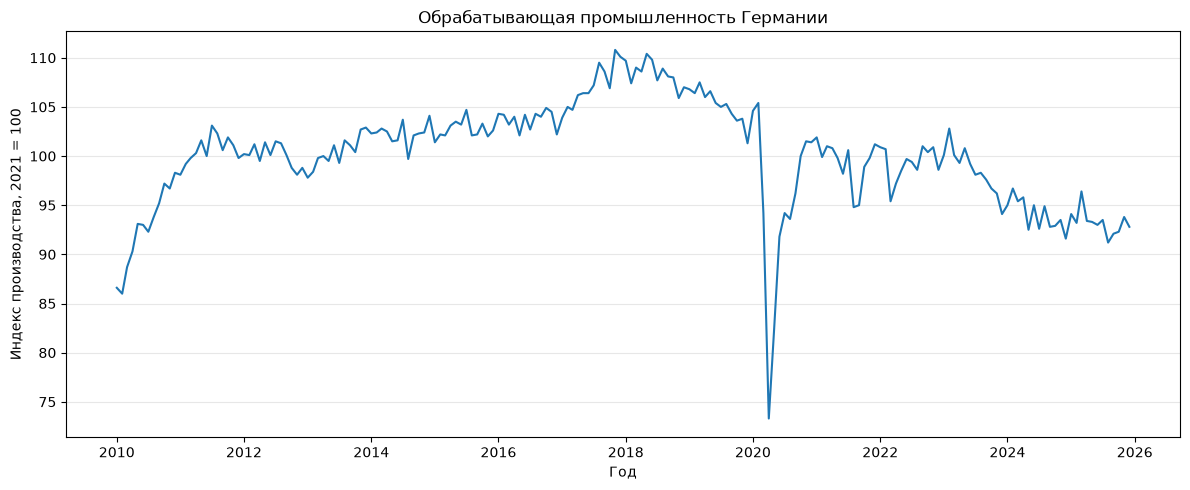

In [39]:
manufacturing = (
    production.loc[production['nace_r2'].eq('C')]
    .sort_values('date')
)

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    manufacturing['date'],
    manufacturing['production_index'],
    linewidth=1.5,
)

ax.set_title('Обрабатывающая промышленность Германии')
ax.set_xlabel('Год')
ax.set_ylabel('Индекс производства, 2021 = 100')
ax.grid(axis='y', alpha=0.3)

fig.tight_layout()
fig.savefig(
    '../figure/industry_C_index.png',
    dpi=300,
    bbox_inches='tight',
)

plt.show()

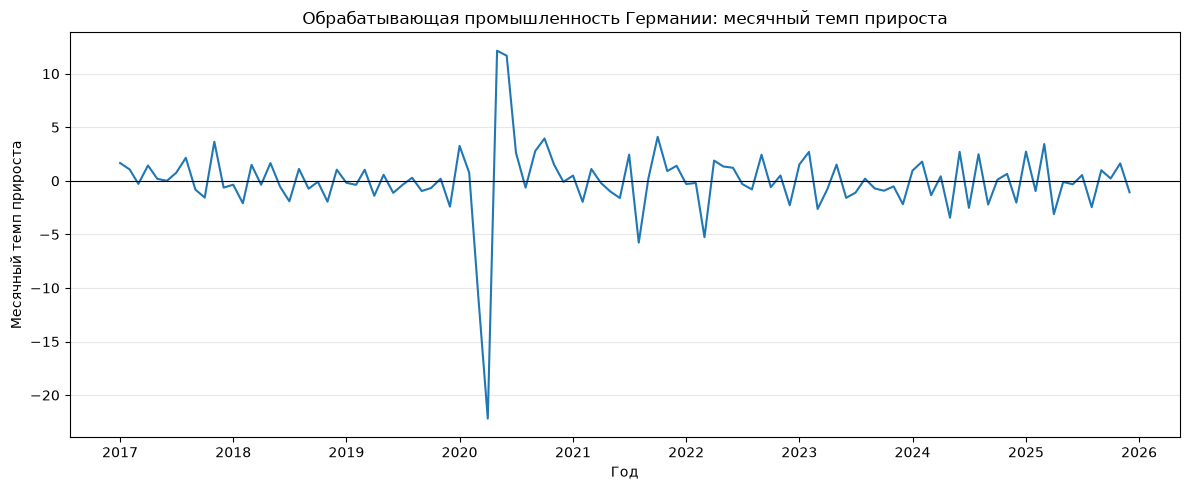

In [40]:
manufacturing = (
    production.loc[production['nace_r2'].eq('C')]
    .sort_values('date')
)
manufacturing = manufacturing[manufacturing['date'] >= '2017-01']
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    manufacturing['date'],
    manufacturing['production_mom_pct'],
    linewidth=1.5,
)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Обрабатывающая промышленность Германии: месячный темп прироста')
ax.set_xlabel('Год')
ax.set_ylabel('Месячный темп прироста')
ax.grid(axis='y', alpha=0.3)
fig.tight_layout()
fig.savefig(
    '../figure/industry_growth.png',
    dpi=300,
    bbox_inches='tight',
)
plt.show()

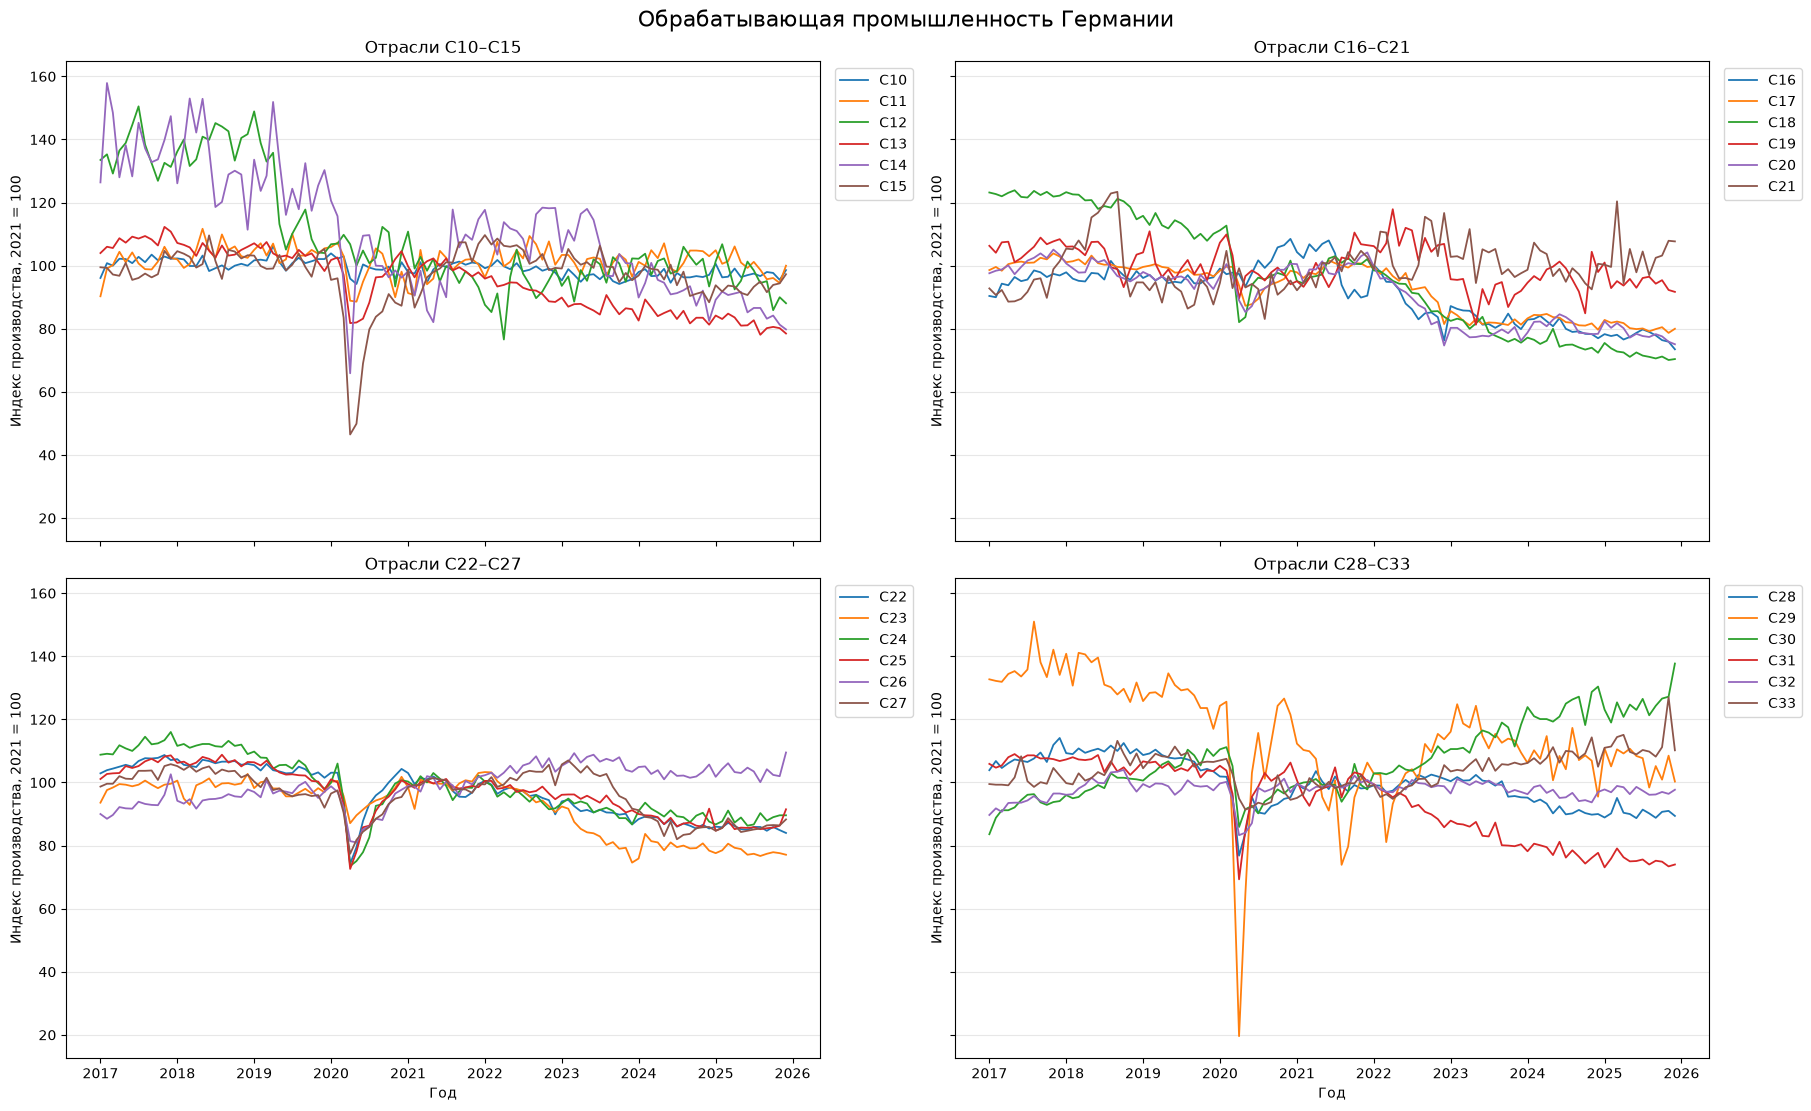

In [41]:
sectors = [f'C{i}' for i in range(10, 34)]
groups = [sectors[i:i + 6] for i in range(0, 24, 6)]

fig, axes = plt.subplots(
    2, 2,
    figsize=(18, 11),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)

for ax, group in zip(axes.flat, groups):
    for j, sector in enumerate(group):
        subset = production.loc[
            production['nace_r2'].eq(sector)
            & production['date'].ge('2017-01-01')
        ].sort_values('date')

        ax.plot(
            subset['date'],
            subset['production_index'],
            label=sector,
            color=plt.get_cmap('tab10')(j),
            linewidth=1.3,
        )

    ax.set_title(f'Отрасли {group[0]}–{group[-1]}')
    ax.set_ylabel('Индекс производства, 2021 = 100')
    ax.grid(axis='y', alpha=0.3)
    ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))

for ax in axes[-1, :]:
    ax.set_xlabel('Год')
fig.suptitle('Обрабатывающая промышленность Германии', fontsize=16)

fig.savefig(
    '../figure/industry_index.png',
    dpi=300,
    bbox_inches='tight',
)
plt.show()

In [42]:
annual = (
    production.loc[
        production['nace_r2'].isin([f'C{i}' for i in range(10, 34)])
    ]
    .assign(year=lambda x: x['date'].dt.year)
    .groupby(['nace_r2', 'year'])['production_index']
    .mean()
    .unstack('year')
)

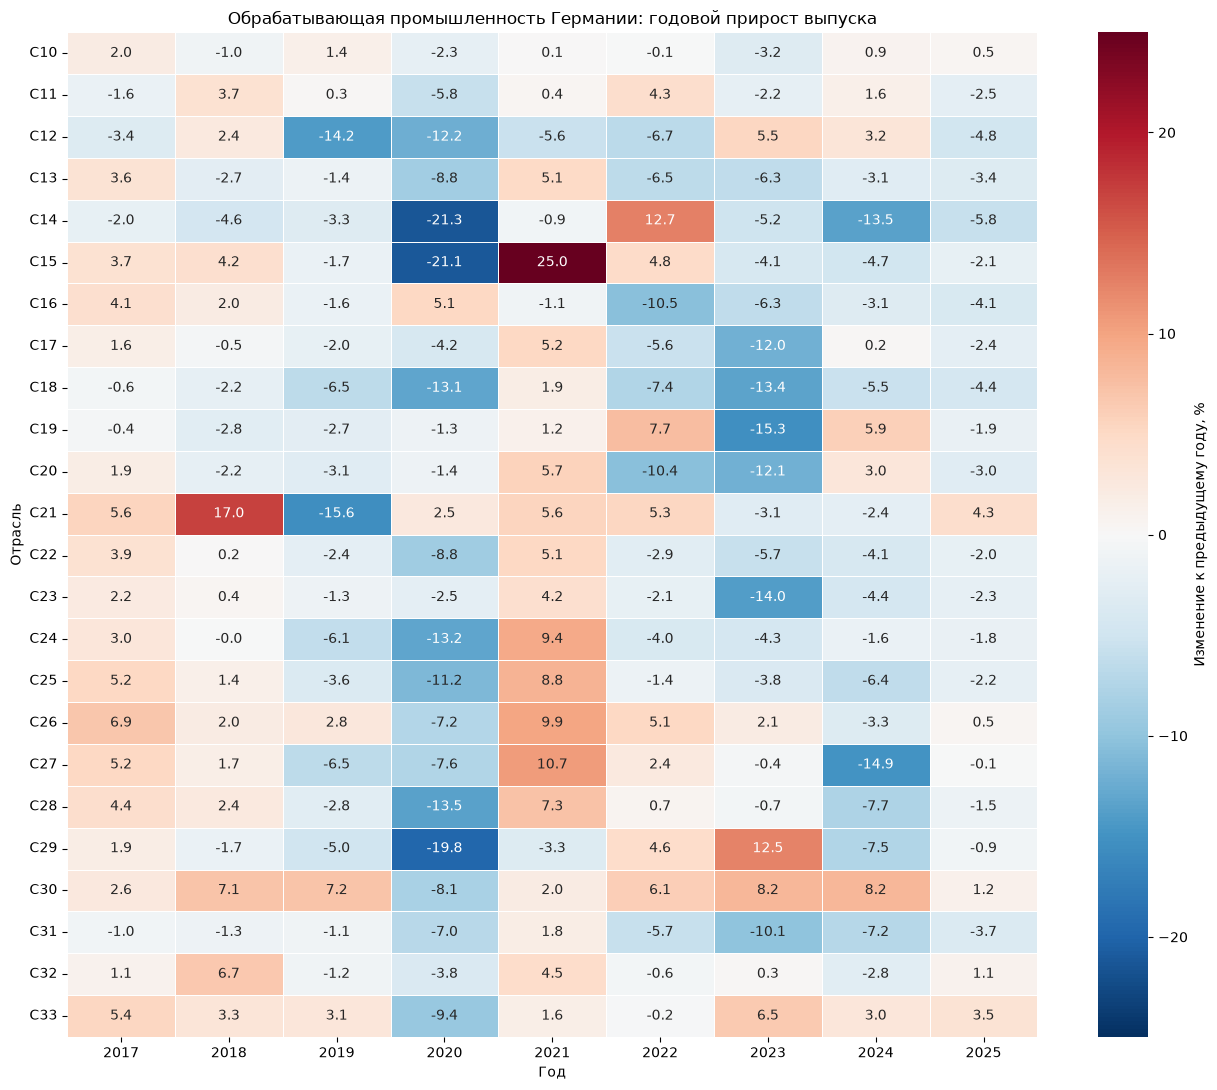

In [43]:
annual_growth = (
    annual.sort_index(axis=1)
    .pct_change(axis='columns', fill_method=None)
    .mul(100)
)

heatmap_data = annual_growth.loc[
    [f'C{i}' for i in range(10, 34)],
    list(range(2017, 2026)),
]

limit = heatmap_data.abs().max().max()

fig, ax = plt.subplots(figsize=(13, 11))

sns.heatmap(
    heatmap_data,
    cmap='RdBu_r',
    center=0,
    vmin=-limit,
    vmax=limit,
    annot=True,
    fmt='.1f',
    linewidths=0.4,
    cbar_kws={'label': 'Изменение к предыдущему году, %'},
    ax=ax,
)

ax.set_title('Обрабатывающая промышленность Германии: годовой прирост выпуска')
ax.set_xlabel('Год')
ax.set_ylabel('Отрасль')
ax.tick_params(axis='y', rotation=0)

fig.tight_layout()

fig.savefig(
    '../figure/industry_annual_growth_heatmap.png',
    dpi=300,
    bbox_inches='tight',
)
plt.show()

In [44]:
production.to_csv(
    '../data/processed/production_monthly.csv',
    index=False,
    date_format='%Y-%m-%d',
)

annual.reset_index().to_csv(
    '../data/processed/production_annual.csv',
    index=False,
)

annual_growth.reset_index().to_csv(
    '../data/processed/production_annual_growth.csv',
    index=False,
)